# 6. VISUALIZACIONES planetas

Para realizar las visualizaciones correspondientes para checkear nuestra hipotesis:
Se necesitan hacer diferentes variables intermedias y agrupaciones algo complicadas.
Ademas tengo que hacer y llamar una funcion en los diferentes calculos de diferentes visualizaciones, para rellenar los graficos numericamente

In [2]:
def etiquetas(ax, total):
    for barras in ax.containers:
        ax.bar_label(barras,fmt=lambda n: f"{n:.0f} ({n / total:.1%})",padding=3)

Carga de archivos

In [3]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

if ROOT.name == "jupyter":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CLEAN = ROOT / "CLEAN"
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.calculos_visualizaciones.funciones import etiquetas

CSV_FILE =  "dataset_merged.csv"
df = pd.read_csv(CLEAN / "dataset_merged.csv")

# 9. Arquitectura: pequenos interiores y gigantes exteriores

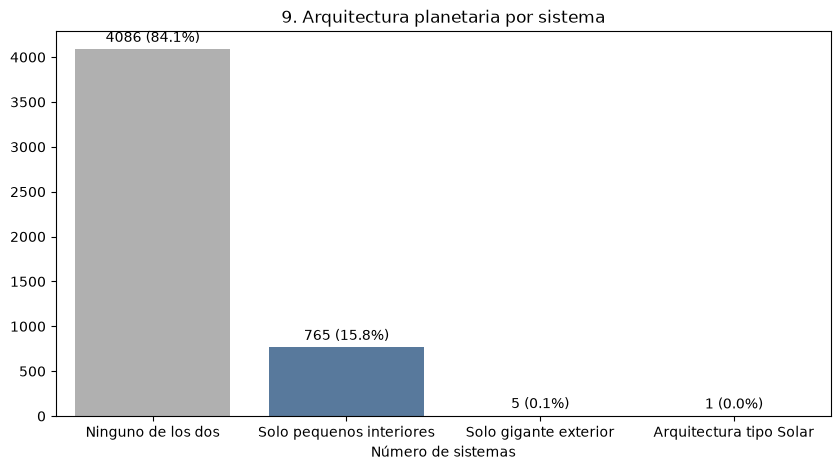

In [4]:
validos_orbita = ((df["st_mass_y"] > 0)& (df["st_mass_y"] < 100)& (df["pl_orbper_y"] > 0))

df["a_ua"] = float("nan")

df.loc[validos_orbita, "a_ua"] = (df.loc[validos_orbita, "st_mass_y"]* (df.loc[validos_orbita, "pl_orbper_y"] / 365.25) ** 2) ** (1 / 3)

df["pequeno_interior"] = (df["pl_rade_y"].between(0.5, 1.6)& (df["a_ua"] < 1.5))

df["gigante_exterior"] = ((df["pl_rade_y"] >= 8)& (df["a_ua"] >= 3))

arquitectura = df.groupby("hostname").agg(
    pequenos_interiores=("pequeno_interior", "any"),
    gigantes_exteriores=("gigante_exterior", "any")
)
arquitectura["tipo"] = "Ninguno de los dos"
arquitectura.loc[arquitectura["pequenos_interiores"] & ~arquitectura["gigantes_exteriores"],"tipo"] = "Solo pequenos interiores"
arquitectura.loc[ ~arquitectura["pequenos_interiores"] & arquitectura["gigantes_exteriores"],"tipo"] = "Solo gigante exterior"
arquitectura.loc[arquitectura["pequenos_interiores"] & arquitectura["gigantes_exteriores"],"tipo"] = "Arquitectura tipo Solar"

conteo_arquitectura = arquitectura["tipo"].value_counts().reindex([
    "Ninguno de los dos",
    "Solo pequenos interiores",
    "Solo gigante exterior",
    "Arquitectura tipo Solar"
], fill_value=0)
colores=["#B0B0B0", "#4C78A8", "#E9C46A", "#2A9D8F"]

plt.figure(figsize=(10, 5))
sns.barplot( x=conteo_arquitectura.index ,y=conteo_arquitectura.values ,
            hue=conteo_arquitectura.index,palette=colores)

plt.title("9. Arquitectura planetaria por sistema")
plt.xlabel("Número de sistemas")
plt.ylabel("")
etiquetas(plt.gca(), conteo_arquitectura.sum())
plt.savefig(ROOT / "imagenes" /"9. Arquitectura planetaria por sistema.png",dpi=300,bbox_inches="tight")

plt.show()

# 10. Excentricidad de las orbitas

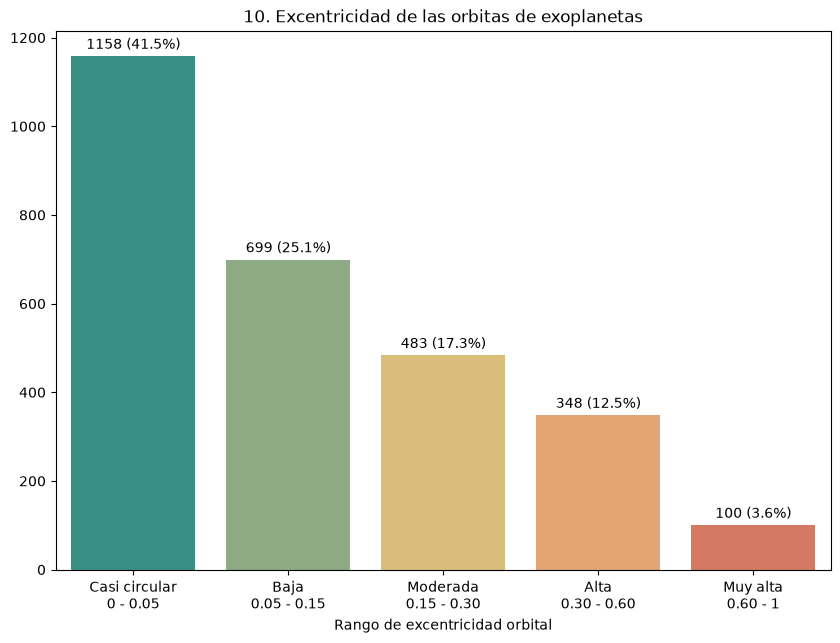

In [5]:


excentricidades = df["pl_orbeccen_y"].dropna()
excentricidades = excentricidades[(excentricidades >= 0) & (excentricidades < 1)]
rangos_excentricidad = pd.cut(excentricidades,bins=[-0.001, 0.05, 0.15, 0.30, 0.60, 1],
    labels=["Casi circular\n0 - 0.05","Baja\n0.05 - 0.15","Moderada\n0.15 - 0.30","Alta\n0.30 - 0.60","Muy alta\n0.60 - 1"],
    include_lowest=True)
conteo_excentricidad = rangos_excentricidad.value_counts().reindex(
    rangos_excentricidad.cat.categories, fill_value=0)

colores=["#2A9D8F", "#8AB17D", "#E9C46A", "#F4A261", "#E76F51"]

plt.figure(figsize=(10, 7))
sns.barplot(x=conteo_excentricidad .index , y=conteo_excentricidad.values,
            hue=conteo_excentricidad .index,palette=colores)

plt.title("10. Excentricidad de las orbitas de exoplanetas")
plt.xlabel("Rango de excentricidad orbital")
plt.ylabel("")
etiquetas(plt.gca(), conteo_excentricidad.sum())
plt.savefig(ROOT / "imagenes" /"10. Excentricidad de las orbitas de exoplanetas.png",dpi=300,bbox_inches="tight")

plt.show()

# 11. Extension orbital: a_max / a_min en sistemas con 2 o mas planetas

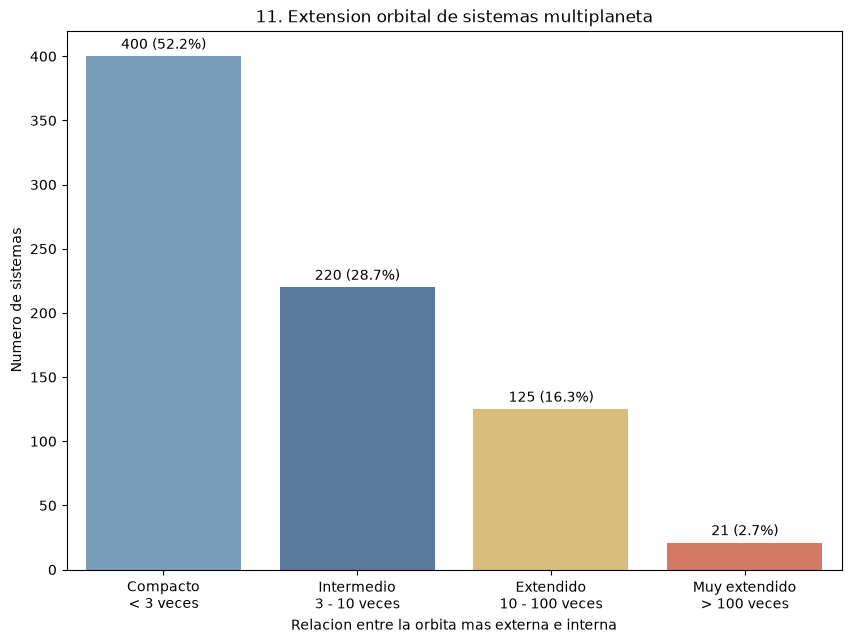

In [6]:
distancias = df.dropna(subset=["a_ua"]).groupby("hostname")["a_ua"].agg(
    planetas_con_distancia="count",
    a_min="min",
    a_max="max")
distancias = distancias[distancias["planetas_con_distancia"] >= 2].copy()
distancias["extension_orbital"] = distancias["a_max"] / distancias["a_min"]

rangos_extension = pd.cut(distancias["extension_orbital"],bins=[1, 3, 10, 100, float("inf")],
    labels=["Compacto\n< 3 veces","Intermedio\n3 - 10 veces","Extendido\n10 - 100 veces","Muy extendido\n> 100 veces"],
    include_lowest=True,
    right=False)
conteo_extension = rangos_extension.value_counts().reindex(
    rangos_extension.cat.categories, fill_value=0)

colores=["#6D9DC5", "#4C78A8", "#E9C46A", "#E76F51"]

plt.figure(figsize=(10, 7))
sns.barplot(x=conteo_extension.index , y=conteo_extension.values,
            hue=conteo_extension.index,palette=colores)

plt.title("11. Extension orbital de sistemas multiplaneta")
plt.xlabel("Relacion entre la orbita mas externa e interna")
plt.ylabel("Numero de sistemas")
etiquetas(plt.gca(), conteo_extension.sum())
plt.savefig(ROOT / "imagenes" /"11. Extension orbital en sistemas con 2 o mas planetas.png",dpi=300,bbox_inches="tight")

plt.show()

# 12.Gráfico de dispersión: tamaño y periodo orbital de los planetas

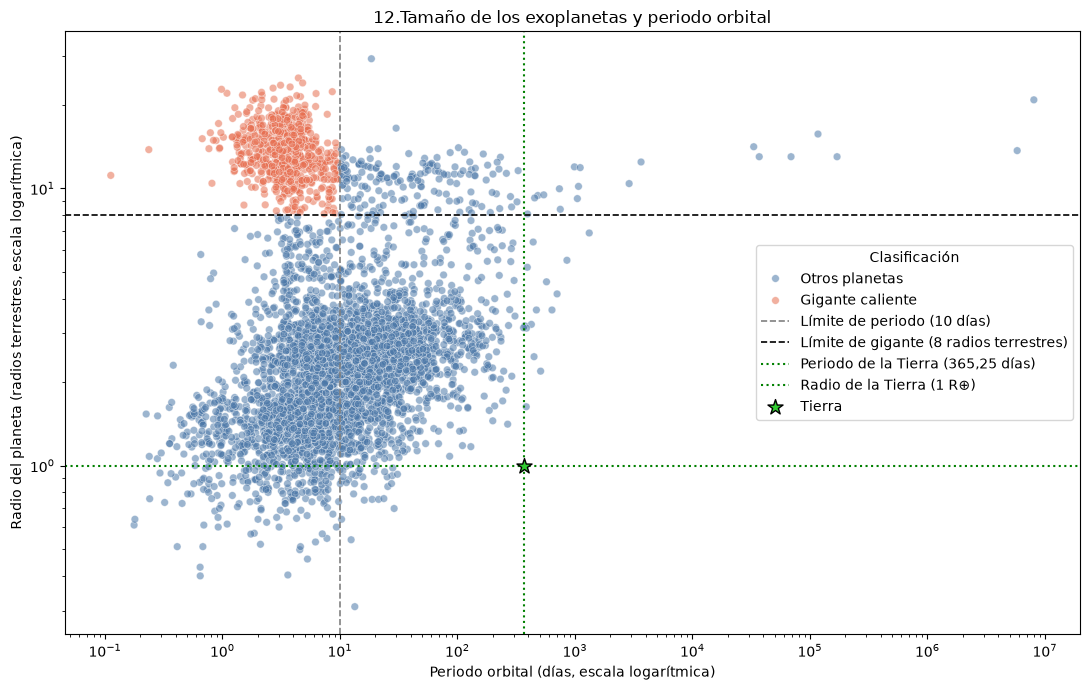

In [14]:
df["gigante_caliente"] = (
    (df["pl_rade_y"] >= 8)
    & (df["pl_orbper_y"] < 10)
)

planetas_grafico = (df.drop_duplicates(subset=["hostname", "pl_name"]).dropna(subset=["pl_orbper_y", "pl_rade_y"]).copy())
planetas_grafico = planetas_grafico[(planetas_grafico["pl_orbper_y"] > 0)& (planetas_grafico["pl_rade_y"] > 0)]
planetas_grafico["clasificacion"] = (planetas_grafico["gigante_caliente"].map({True: "Gigante caliente",False: "Otros planetas"}))

plt.figure(figsize=(11, 7))

sns.scatterplot(data=planetas_grafico,x="pl_orbper_y",y="pl_rade_y",hue="clasificacion",hue_order=["Otros planetas", "Gigante caliente"],palette={
        "Otros planetas": "#4C78A8",
        "Gigante caliente": "#E76F51"},alpha=0.55,s=30)

plt.xscale("log")
plt.yscale("log")

plt.axvline(x=10,color="gray",linestyle="--",linewidth=1.2,label="Límite de periodo (10 días)")

plt.axhline(y=8,color="black",linestyle="--",linewidth=1.2,label="Límite de gigante (8 radios terrestres)")

# Posición de la Tierra: 365.25 días y 1 radio terrestre

plt.axvline(x=365.25,color="green",linestyle=":",linewidth=1.5,label="Periodo de la Tierra (365,25 días)")

plt.axhline(y=1,color="green",linestyle=":",linewidth=1.5,label="Radio de la Tierra (1 R⊕)")

plt.scatter(365.25,1,color="limegreen",edgecolor="black",s=130,marker="*",zorder=10,label="Tierra")

plt.title("12.Tamaño de los exoplanetas y periodo orbital")
plt.xlabel("Periodo orbital (días, escala logarítmica)")
plt.ylabel("Radio del planeta (radios terrestres, escala logarítmica)")
plt.legend(title="Clasificación")
plt.tight_layout()
plt.savefig(ROOT / "imagenes" / "12.Gráfico de dispersión, tamaño y periodo orbital de los planetas.png",dpi=300,bbox_inches="tight")

plt.show()